# Projet- Détection DDoS et généralisation à des attaques non observées

Corentin CALVEZ et Lubin TERRIEN

## Question de recherche
Est-ce qu’un modèle entraîné sur certaines familles de DDoS peut reconnaître une stratégie de DDoS qu’il n’a jamais vue ?  Le jeu de données est CIC-DDoS2019, publié sous forme de 17 fichiers parquet avec 77 caractéristiques de flux et 18 étiquettes brutes.

## Hypothèses
- **H1** - La classification multiclasses est plus difficile que la classification binaire.
- **H2** - La généralisation à une famille non observée dépend fortement de la famille laissée de côté : certains mécanismes sont reconnaissables à partir de la structure du flux partagée, d’autres ne sont que mémorisés.
- **H3** - Une fraction des 77 caractéristiques conserve l’essentiel de la performance, et un ensemble de caractéristiques plus petit réduit le coût d’inférence.

Pour télécharger le jeu de données :
```bash
uv run kaggle datasets download dhoogla/cicddos2019
```

# 01 - Phase 1 : Exploratory data analysis

In [20]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
DATA = ROOT / "dataset"
RES = ROOT / "results"
FIG = ROOT / "figures"
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

BENIGN = "Benign"
SEEDS = [42, 43, 44]
CAP = 20_000

In [21]:
def load_dataset(data_dir=None):
    files = sorted(Path(data_dir or DATA).glob("*.parquet"))
    frames = []
    for path in files:
        frame = pd.read_parquet(path)
        frame.columns = [str(column).strip() for column in frame.columns]
        frame["src_file"] = path.name
        frames.append(frame)
    raw = pd.concat(frames, ignore_index=True)
    raw["Label"] = raw["Label"].astype(str).str.strip().replace({"UDP-lag": "UDPLag"})
    features = [column for column in raw.columns if column not in ("Label", "src_file")]
    X = raw[features].astype("float64")
    y_family = raw["Label"].astype("string").rename("family")
    y_binary = (y_family != BENIGN).astype("int8").rename("binary")
    meta = pd.DataFrame(
        {"src_file": raw["src_file"].astype("string"), "label": y_family.to_numpy()},
        index=X.index,
    )
    return X, y_family, y_binary, meta

In [22]:
# Chargement du jeu de données et affichage des dimensions, des familles et des fichiers
X, y_family, y_binary, meta = load_dataset()
print(f"lignes      : {len(X):,}")
print(f"features    : {X.shape[1]}")
print(f"familles    : {y_family.nunique()}  (Benign + {y_family.nunique() - 1} attack families)")
print(f"fichiers    : {meta['src_file'].nunique()}")
print(f"NaN / inf   : {int(X.isna().sum().sum())} / {int(np.isinf(X.to_numpy()).sum())}")
display(meta.head())
display(X.head(3))

lignes      : 431,371
features    : 77
familles    : 17  (Benign + 16 attack families)
fichiers    : 17
NaN / inf   : 0 / 0


,src_file,label
0,DNS-testing.parquet,DrDoS_DNS
1,DNS-testing.parquet,DrDoS_DNS
2,DNS-testing.parquet,DrDoS_DNS
3,DNS-testing.parquet,DrDoS_DNS
4,DNS-testing.parquet,DrDoS_DNS


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,...,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,17.0,48.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,6.133333e+07,4.166667e+04,48.0,0.0,48.0,48.0,48.0,48.0,0.0,48.0,48.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2208.0,1472.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2944.0,0.0,0.0,-1.0,-1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,17.0,2.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,1.472000e+09,1.000000e+06,2.0,0.0,2.0,2.0,2.0,2.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2208.0,1472.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2944.0,0.0,0.0,-1.0,-1.0,1.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,17.0,1.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,2.944000e+09,2.000000e+06,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2208.0,1472.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2944.0,0.0,0.0,-1.0,-1.0,1.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,rows,share_pct,kind
family,,,
DrDoS_NTP,121368,28.135,Attack
TFTP,98917,22.931,Attack
Benign,97831,22.679,Benign
Syn,49373,11.446,Attack
UDP,18090,4.194,Attack
DrDoS_UDP,10420,2.416,Attack
UDPLag,8927,2.069,Attack
MSSQL,8523,1.976,Attack
DrDoS_MSSQL,6212,1.44,Attack


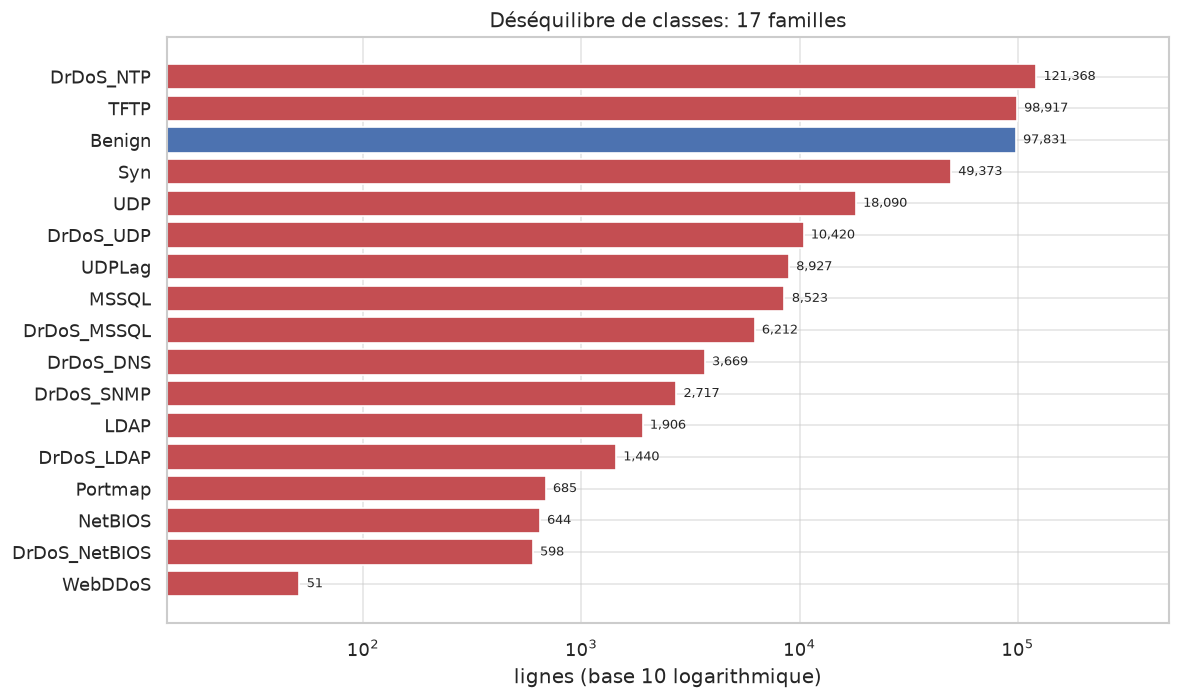

In [23]:
# Comptage des lignes par famille et par protocole, avec visualisation de la répartition des familles et de la relation famille * protocole.
counts = y_family.value_counts().rename("rows").to_frame()
counts["share_pct"] = (100 * counts["rows"] / counts["rows"].sum()).round(3)
counts["kind"] = np.where(counts.index == BENIGN, "Benign", "Attack")
display(counts)
counts.to_csv(RES / "eda_family_counts.csv")

fig, ax = plt.subplots(figsize=(10, 6))
order = counts.index[::-1]
colors = ["#4c72b0" if label == BENIGN else "#c44e52" for label in order]
ax.barh(order, counts.loc[order, "rows"], color=colors)
ax.set_xscale("log")
ax.set_xlabel("lignes (base 10 logarithmique)")
ax.set_title("Déséquilibre de classes: 17 familles")
for i, label in enumerate(order):
    ax.text(counts.loc[label, "rows"] * 1.08, i, f"{counts.loc[label, 'rows']:,}", va="center", fontsize=8)
ax.margins(x=0.18)
fig.tight_layout()
fig.savefig(FIG / "01_eda_family_imbalance.png", bbox_inches="tight")
plt.show()

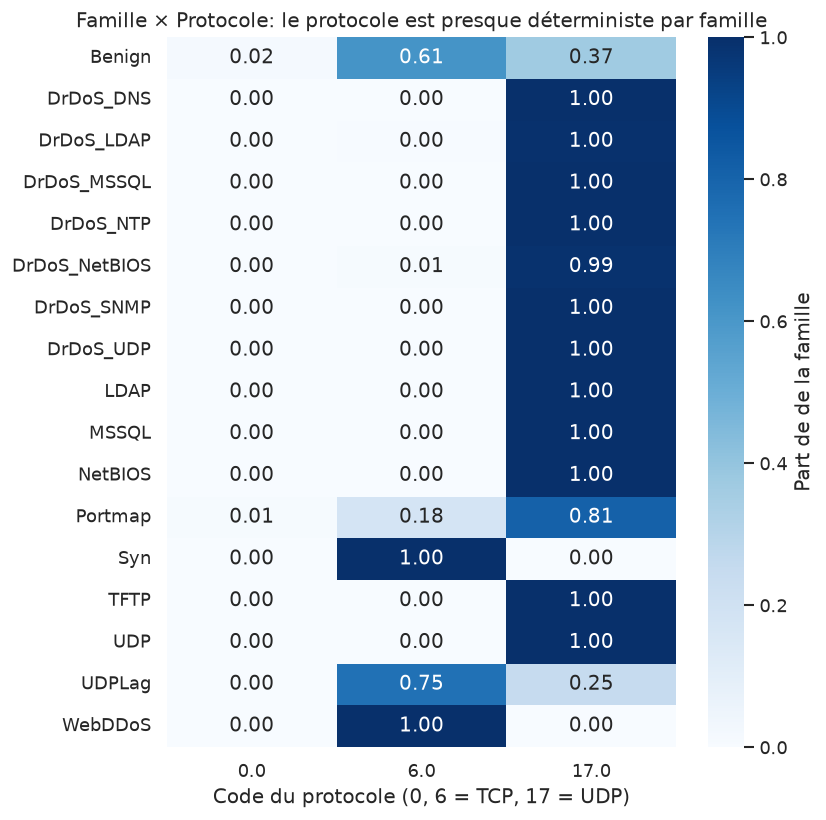

Syn TCP : 0.9983
MSSQL UDP : 0.9994
UDP UDP : 0.9998


In [24]:
# Analyse de la relation entre les familles et les protocoles
protocol = pd.crosstab(y_family, X["Protocol"])
protocol_share = protocol.div(protocol.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(
    protocol_share,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar_kws={"label": "Part de de la famille"},
    ax=ax,
)
ax.set_title("Famille × Protocole: le protocole est presque déterministe par famille")
ax.set_xlabel("Code du protocole (0, 6 = TCP, 17 = UDP)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG / "01_eda_family_protocol.png", bbox_inches="tight")
plt.show()

print("Syn TCP :", f"{protocol_share.loc['Syn', 6]:.4f}")
print("MSSQL UDP :", f"{protocol_share.loc['MSSQL', 17]:.4f}")
print("UDP UDP :", f"{protocol_share.loc['UDP', 17]:.4f}")

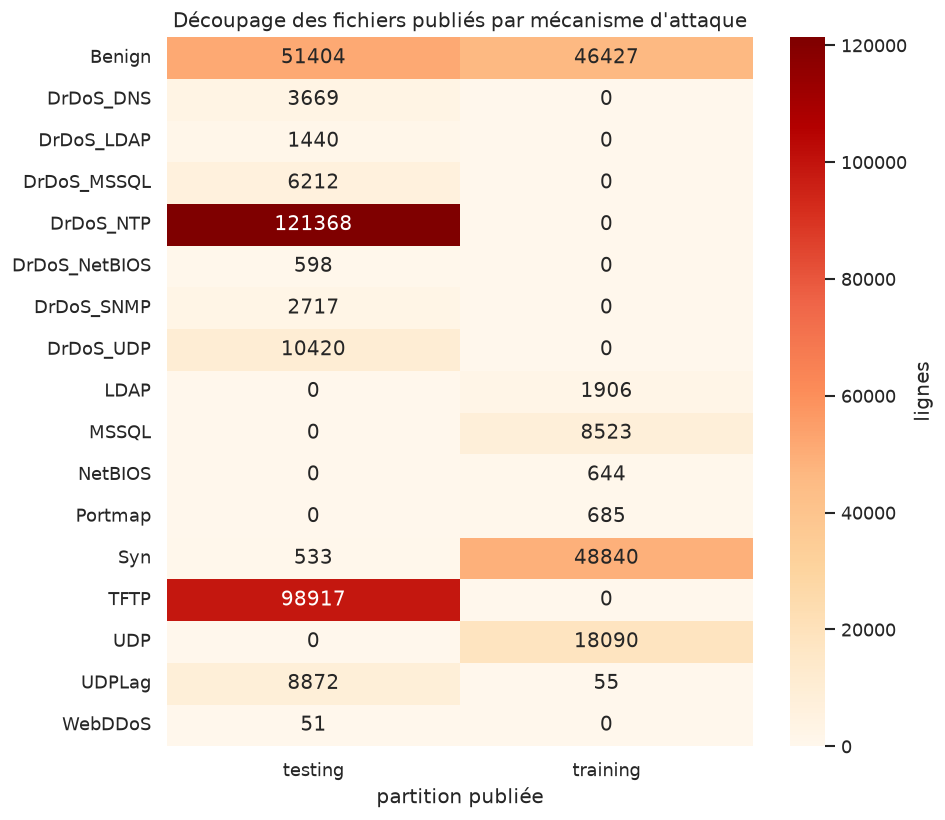

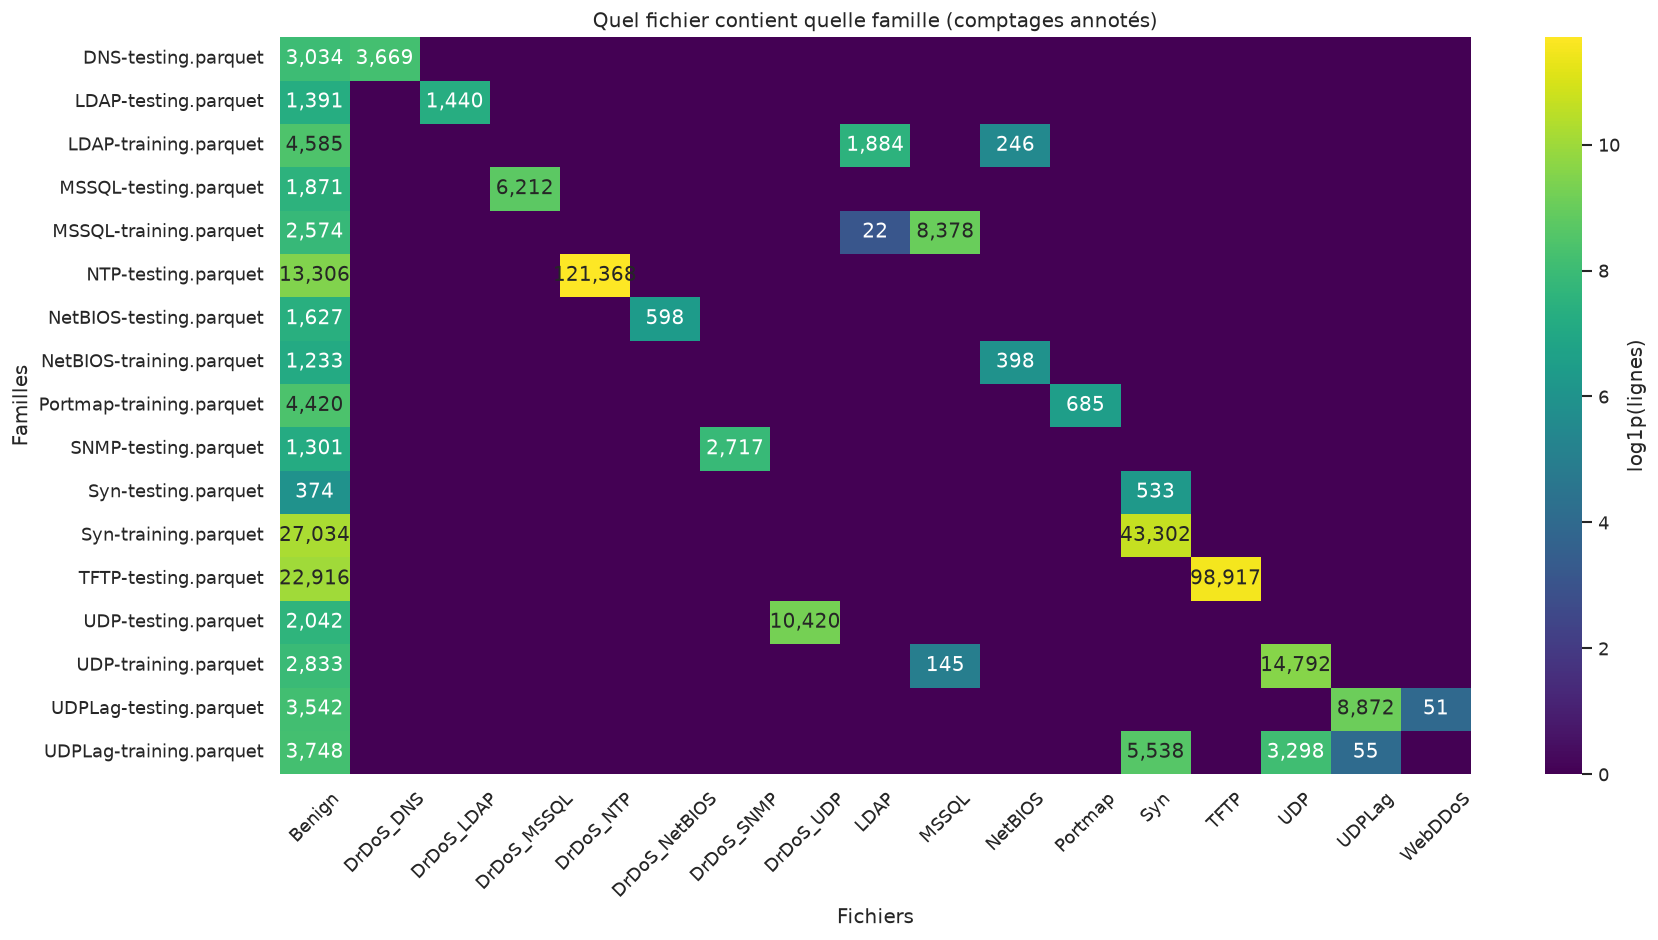

seulement dans les fichiers -testing : ['DrDoS_DNS', 'DrDoS_LDAP', 'DrDoS_MSSQL', 'DrDoS_NTP', 'DrDoS_NetBIOS', 'DrDoS_SNMP', 'DrDoS_UDP', 'TFTP', 'WebDDoS']
seulement dans les fichiers -training : ['LDAP', 'MSSQL', 'NetBIOS', 'Portmap', 'UDP']
présent dans les 2: ['Benign', 'Syn', 'UDPLag']


In [25]:
# Audit de fuite de données sur le cadre concaténé brut, avant toute séparation.
meta_audit = meta.copy()
meta_audit["partition"] = meta_audit["src_file"].str.extract(r"-(training|testing)\.parquet")[0]
partition = pd.crosstab(y_family, meta_audit["partition"])

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    partition,
    annot=True,
    fmt="d",
    cmap="OrRd",
    cbar_kws={"label": "lignes"},
    ax=ax,
)
ax.set_title("Découpage des fichiers publiés par mécanisme d'attaque")
ax.set_xlabel("partition publiée")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG / "01_eda_file_partition.png", bbox_inches="tight")
plt.show()

file_family = pd.crosstab(meta_audit["src_file"], y_family)
fig, ax = plt.subplots(figsize=(15, 8))
annot = file_family.map(lambda value: f"{value:,}" if value else "")
sns.heatmap(
    np.log1p(file_family),
    annot=annot,
    fmt="",
    cmap="viridis",
    cbar_kws={"label": "log1p(lignes)"},
    ax=ax,
)
ax.set_title("Quel fichier contient quelle famille (comptages annotés)")
ax.set_xlabel("Fichiers")
ax.set_ylabel("Familles")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIG / "01_eda_file_family_matrix.png", bbox_inches="tight")
plt.show()

only_testing = sorted(
    label for label in partition.index if partition.loc[label].get("training", 0) == 0
)
only_training = sorted(
    label for label in partition.index if partition.loc[label].get("testing", 0) == 0
)
both = sorted(
    label
    for label in partition.index
    if partition.loc[label].get("training", 0) > 0
    and partition.loc[label].get("testing", 0) > 0
)
print("seulement dans les fichiers -testing :", only_testing)
print("seulement dans les fichiers -training :", only_training)
print("présent dans les 2:", both)

In [26]:
def dedupe(X, y, meta=None):
    key = pd.Series(pd.util.hash_pandas_object(X, index=False).to_numpy(), index=X.index)
    grouped = y.groupby(key, sort=False)
    labels = grouped.first()
    n_labels = grouped.nunique()
    conflicts = n_labels[n_labels > 1].index
    if len(conflicts):
        subset = pd.DataFrame({"hash": key, "y": y}).loc[lambda frame: frame["hash"].isin(conflicts)]
        majority = subset.groupby("hash")["y"].agg(
            lambda values: sorted(values.value_counts().loc[lambda counts: counts == counts.max()].index)[0]
        )
        labels.loc[conflicts] = majority.reindex(conflicts)
    keep = ~key.duplicated(keep="first")
    X_out = X.loc[keep].reset_index(drop=True)
    y_out = pd.Series(labels.reindex(key[keep]).to_numpy(), index=X_out.index, name=y.name)
    X_out.attrs["dedupe"] = {
        "rows_in": int(len(X)),
        "rows_out": int(len(X_out)),
        "rows_removed": int(len(X) - len(X_out)),
        "rows_in_duplicate_groups": int(key.duplicated(keep=False).sum()),
        "conflicting_hashes": int(len(conflicts)),
    }
    if meta is None:
        return X_out, y_out
    meta_out = meta.loc[keep].reset_index(drop=True)
    return X_out, y_out, meta_out

,check,value
0,lignes dans des groupes de doublons exacts,21347
1,hashs de features présents dans >1 fichier source,8858
2,hashs de features avec labels conflictuels,5289
3,lignes impliquées dans des hash de features av...,12957
4,lignes supprimées par le dedupe,12487
5,lignes après le dedupe,418884


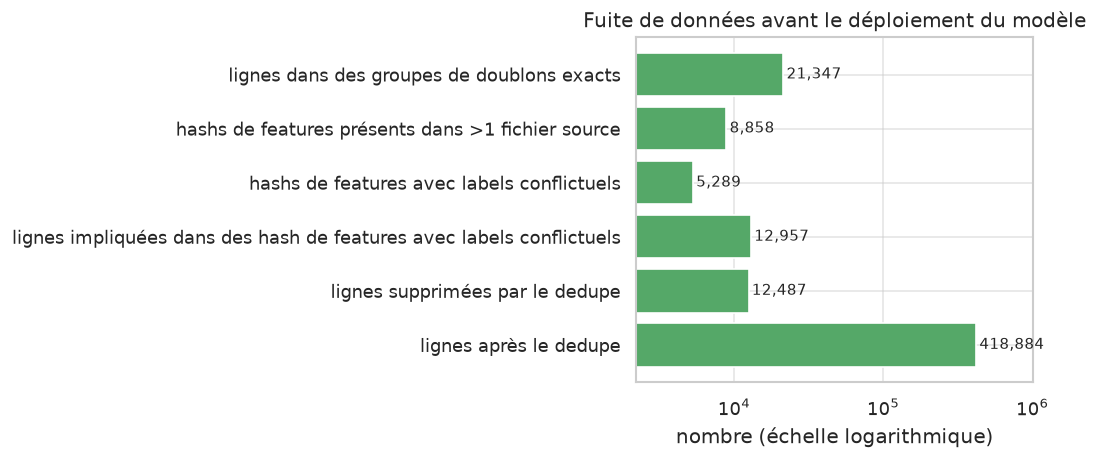

In [27]:
# Audit de fuite de données
feature_names = list(X.columns)
raw_hash = pd.util.hash_pandas_object(X, index=False)
hash_meta = pd.DataFrame({"hash": raw_hash, "src_file": meta["src_file"].to_numpy(), "family": y_family.to_numpy()})

rows_in_dup_groups = int(raw_hash.duplicated(keep=False).sum())
hashes_in_multiple_files = int(
    hash_meta.groupby("hash")["src_file"].nunique().gt(1).sum()
)
labels_per_hash = hash_meta.groupby("hash")["family"].nunique()
conflicting_hashes = int(labels_per_hash.gt(1).sum())
rows_in_conflicts = int(hash_meta["hash"].isin(labels_per_hash[labels_per_hash > 1].index).sum())

X_deduped, y_deduped = dedupe(X, y_family)
dedupe_stats = X_deduped.attrs["dedupe"]

audit = pd.DataFrame(
    {
        "check": [
            "lignes dans des groupes de doublons exacts",
            "hashs de features présents dans >1 fichier source",
            "hashs de features avec labels conflictuels",
            "lignes impliquées dans des hash de features avec labels conflictuels",
            "lignes supprimées par le dedupe",
            "lignes après le dedupe",
        ],
        "value": [
            rows_in_dup_groups,
            hashes_in_multiple_files,
            conflicting_hashes,
            rows_in_conflicts,
            dedupe_stats["rows_removed"],
            dedupe_stats["rows_out"],
        ],
    }
)
display(audit)
audit.to_csv(RES / "eda_leakage_audit.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(audit["check"][::-1], audit["value"][::-1], color="#55a868")
ax.set_xscale("log")
ax.set_xlabel("nombre (échelle logarithmique)")
ax.set_title("Fuite de données avant le déploiement du modèle")
for i, value in enumerate(audit["value"][::-1]):
    ax.text(value * 1.05, i, f"{value:,}", va="center", fontsize=9)
ax.margins(x=0.2)
fig.tight_layout()
fig.savefig(FIG / "01_eda_leakage_audit.png", bbox_inches="tight")
plt.show()

In [28]:
# Choix des six features avec le signal univarié le plus fort, sur un échantillon stratifié (EDA uniquement ; aucune décision de sélection de modèle ici).
sample_parts = []
for _, group in X.assign(_family=y_family.to_numpy()).groupby("_family", sort=False):
    sample_parts.append(group.sample(n=min(1500, len(group)), random_state=42))
sample = pd.concat(sample_parts, ignore_index=True)
mi = mutual_info_classif(
    sample[feature_names],
    sample["_family"],
    discrete_features=False,
    random_state=42,
)
mi = pd.Series(mi, index=feature_names).sort_values(ascending=False)
display(mi.head(20).rename("mutual_info").to_frame())
mi.to_csv(RES / "eda_mutual_info.csv", header=["mutual_info"])
top6 = mi.head(6).index.tolist()
print("top 6:", top6)

,mutual_info
Avg Packet Size,1.861460
Packet Length Max,1.844378
Fwd Packet Length Min,1.831588
Fwd Packet Length Max,1.831392
Packet Length Mean,1.830967
Avg Fwd Segment Size,1.829035
Fwd Packet Length Mean,1.828267
Packet Length Min,1.826198
Fwd Packets Length Total,1.806746
Subflow Fwd Bytes,1.798098


top 6: ['Avg Packet Size', 'Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Max', 'Packet Length Mean', 'Avg Fwd Segment Size']


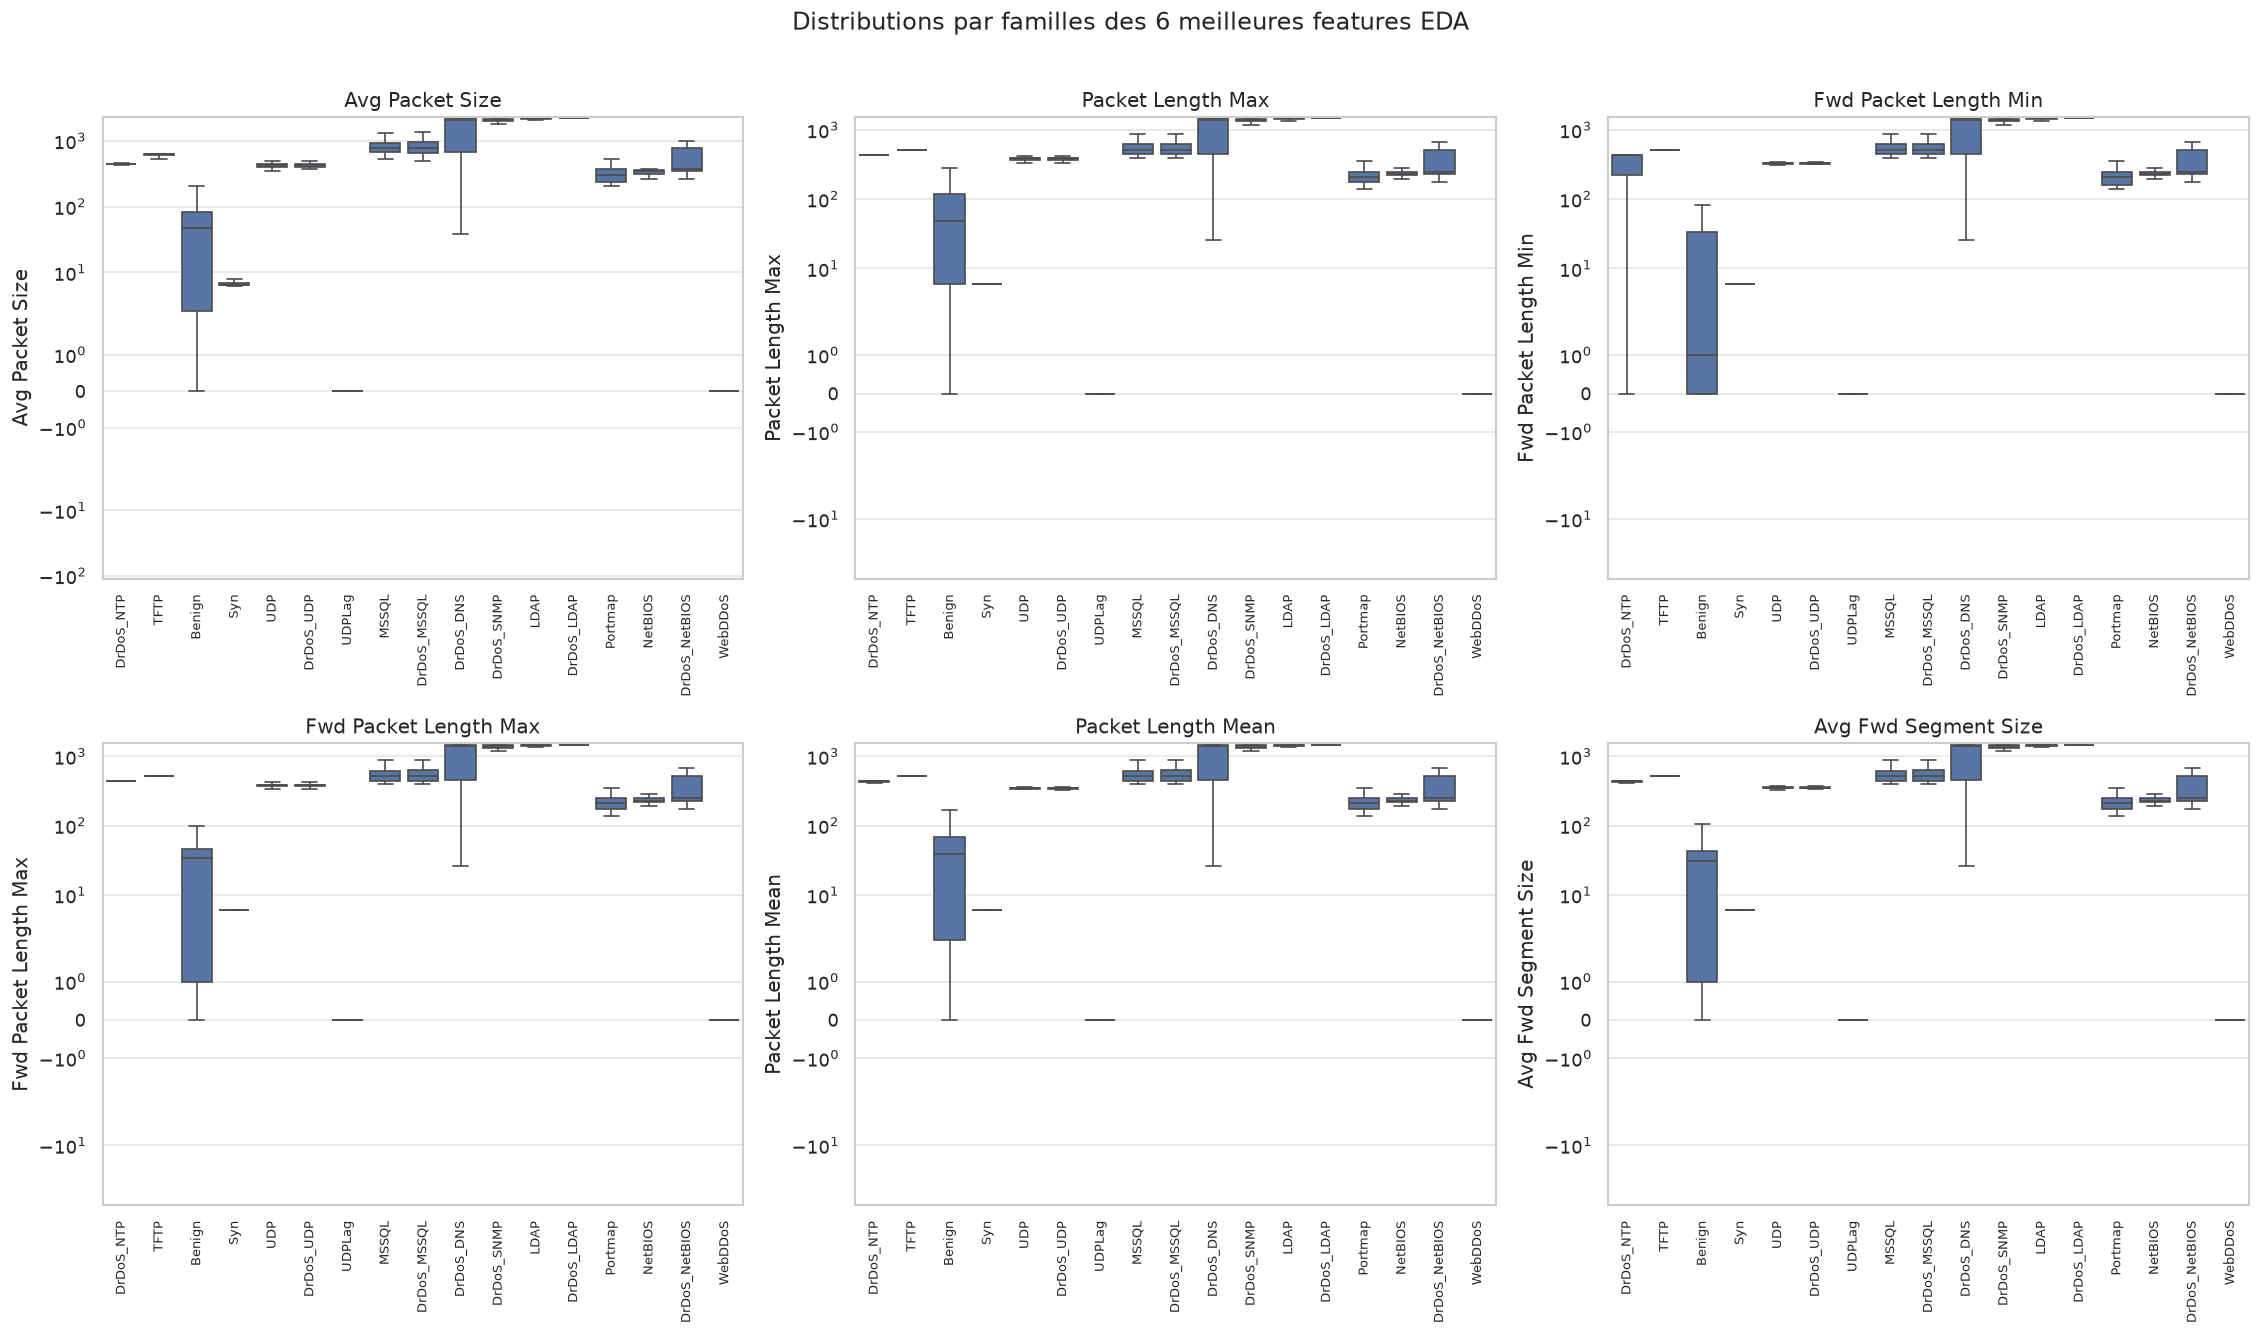

In [29]:
# Visualisation des distributions des six meilleures features, par famille, sur un échantillon stratifié (EDA uniquement ; aucune décision de sélection de modèle ici).
plot_sample = X[top6].sample(n=min(20_000, len(X)), random_state=42).copy()
plot_sample["family"] = y_family.loc[plot_sample.index].to_numpy()
order = y_family.value_counts().index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for ax, feature in zip(axes.ravel(), top6):
    sns.boxplot(
        data=plot_sample,
        x="family",
        y=feature,
        order=order,
        showfliers=False,
        color="#4c72b0",
        ax=ax,
    )
    ax.set_yscale("symlog")
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.suptitle("Distributions par familles des 6 meilleures features EDA", y=1.01)
fig.tight_layout()
fig.savefig(FIG / "01_eda_top_feature_distributions.png", bbox_inches="tight")
plt.show()

## Ce que ce notebook établit

**Observation.** Les 17 étiquettes sont extrêmement déséquilibrées (NTP 121k vs WebDDoS 49). Le protocole détermine presque la famille pour Syn, MSSQL et UDP. Les sept familles `DrDoS_*` n’apparaissent que dans les fichiers `-testing` ; LDAP, MSSQL, NetBIOS, Portmap et UDP n’apparaissent que dans les fichiers `-training`.


**Interprétation ML.** Une séparation aléatoire après déduplication est nécessaire. Le découpage publié mettrait des mécanismes entiers d’un côté, donc un modèle pourrait bien scorer en reconnaissant le fichier/mécanisme plutôt que l’attaque. Les doublons exacts mettraient également la même ligne dans train et test. La déduplication par hash de features supprime les deux raccourcis.

**Interprétation cyber.** `Protocol` est proche d’une table de lookup pour plusieurs familles. Un score élevé en multiclasse peut donc mesurer principalement la reconnaissance du protocole. L’expérience 1 répète la tâche multiclasse sans `Protocol` pour quantifier ce raccourci. Des vecteurs de features identiques avec des labels différents sont une vraie limitation : certains flux de réflexion et d’exploitation sont indistinguables au niveau du flux, donc le bruit d’étiquette est irréductible pour ces paires.

**Limite.** L'analyse EDA est basée sur un échantillon et utilise l'information mutuelle univariée. Elle ne représente pas la sélection de l'expérience 3, qui est ajustée uniquement sur le pli d'entraînement. Le jeu de données est une capture de laboratoire de 2019 et ne représente pas le trafic de production actuel.

# 02 - Phase 2 : Baselines (Benign / DDoS)

## Question
Avant de comparer quoi que ce soit de complexe : quelle est la performance d’un dummy, d’un modèle linéaire et d’un ensemble d’arbres sur la tâche binaire, avec la séparation sans fuite ?

## Protocole
- CIC-DDoS2019 après déduplication : 77 features, répartition en 80/20
- `DummyClassifier(strategy="stratified")` est le palier minimal.
- `LogisticRegression(max_iter=2000, class_weight="balanced")` est la référence linéaire.
- `RandomForestClassifier(n_estimators=300, class_weight="balanced")` est la référence non linéaire.
- La mise à l'échelle et la suppression des caractéristiques constantes sont intégrées au pipeline et ne s'appliquent qu'au modèle d'entraînement.
- Metrics: Macro-F1, Weighted-F1, per-class Precision/Recall/F1, PR-AUC, ROC-AUC, FPR at 95 % recall. L'accuracy est affichée mais n’est pas utilisée pour conclure.


In [30]:
import json
import time
import warnings
from pathlib import Path
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix as sk_confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [31]:
def confusion_matrix(y_true, y_pred, labels):
    matrix = sk_confusion_matrix(y_true, y_pred, labels=list(labels))
    return pd.DataFrame(
        matrix,
        index=pd.Index(list(labels), name="true"),
        columns=pd.Index(list(labels), name="pred"),
    )

In [32]:
def load_deduped(data_dir=None):
    X, y_family, _, meta = load_dataset(data_dir)
    X, y_family, meta = dedupe(X, y_family, meta)
    y_binary = (y_family != BENIGN).astype("int8").rename("binary")
    return X, y_family, y_binary, meta


def split(X, y, seed=42, test_size=0.2):
    return train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed, shuffle=True
    )


def drop_constants(X_train, X_test):
    keep = X_train.columns[X_train.nunique() > 1]
    return X_train[keep].copy(), X_test[keep].copy(), list(keep)


def build_pipeline(clf):
    return Pipeline([("scale", StandardScaler()), ("clf", clf)])


def model(name, seed=42, n_estimators=300):
    if name == "dummy":
        return DummyClassifier(strategy="stratified", random_state=seed)
    if name == "logreg":
        return LogisticRegression(max_iter=2000, class_weight="balanced", random_state=seed)
    if name == "random_forest":
        return RandomForestClassifier(
            n_estimators=n_estimators,
            class_weight="balanced",
            n_jobs=-1,
            random_state=seed,
        )
    raise ValueError(name)


def make_models(seed=42, names=None, n_estimators=300):
    names = names or ["dummy", "logreg", "random_forest"]
    return {name: build_pipeline(model(name, seed, n_estimators)) for name in names}


def fpr_at_tpr95(y_true, scores):
    fpr, tpr, _ = roc_curve(y_true, scores)
    return float(np.interp(0.95, tpr, fpr))


def evaluate(y_true, y_pred, y_proba, classes):
    classes = list(classes)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    proba = np.asarray(y_proba)
    if proba.ndim == 1:
        proba = np.column_stack([1.0 - proba, proba])
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=classes, average=None, zero_division=0
    )
    rows = []
    for index, label in enumerate(classes):
        binary_true = (y_true == label).astype(int)
        binary_pred = (y_pred == label).astype(int)
        tp = int(((binary_true == 1) & (binary_pred == 1)).sum())
        fp = int(((binary_true == 0) & (binary_pred == 1)).sum())
        tn = int(((binary_true == 0) & (binary_pred == 0)).sum())
        fn = int(((binary_true == 1) & (binary_pred == 0)).sum())
        row = {
            "class": label,
            "precision": float(precision[index]),
            "recall": float(recall[index]),
            "f1": float(f1[index]),
            "support": int(support[index]),
            "tp": tp,
            "fp": fp,
            "tn": tn,
            "fn": fn,
            "fpr": float(fp / (fp + tn)) if (fp + tn) else np.nan,
            "specificity": float(tn / (tn + fp)) if (tn + fp) else np.nan,
            "pr_auc": np.nan,
            "roc_auc": np.nan,
            "fpr_at_tpr95": np.nan,
        }
        if 0 < binary_true.sum() < len(binary_true):
            row["pr_auc"] = float(average_precision_score(binary_true, proba[:, index]))
            row["roc_auc"] = float(roc_auc_score(binary_true, proba[:, index]))
            row["fpr_at_tpr95"] = fpr_at_tpr95(binary_true, proba[:, index])
        rows.append(row)
    per_class = pd.DataFrame(rows).set_index("class", drop=False)
    per_class.index.name = None
    if len(classes) == 2:
        positive = per_class.iloc[1]
        pr_auc = float(positive["pr_auc"])
        roc_auc = float(positive["roc_auc"])
        fpr95 = float(positive["fpr_at_tpr95"])
        fpr = float(positive["fpr"])
    else:
        pr_auc = float(np.nanmean(per_class["pr_auc"]))
        roc_auc = float(np.nanmean(per_class["roc_auc"]))
        fpr95 = float(np.nanmean(per_class["fpr_at_tpr95"]))
        fpr = float(np.nanmean(per_class["fpr"]))
    return {
        "n_test": int(len(y_true)),
        "n_classes": len(classes),
        "macro_f1": float(f1_score(y_true, y_pred, labels=classes, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=classes, average="weighted", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "pr_auc": pr_auc,
        "roc_auc": roc_auc,
        "fpr": fpr,
        "fpr_at_tpr95": fpr95,
        "per_class": per_class,
    }


def fit_and_score(pipeline, X_train, y_train, X_test, y_test):
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    y_pred = pipeline.predict(X_test)
    predict_seconds = time.perf_counter() - start
    y_proba = pipeline.predict_proba(X_test)
    classes = list(pipeline.named_steps["clf"].classes_)
    metrics = evaluate(y_test, y_pred, y_proba, classes)
    return {
        "metrics": metrics,
        "y_pred": np.asarray(y_pred),
        "classes": classes,
        "fit_seconds": float(fit_seconds),
        "predict_seconds": float(predict_seconds),
        "n_train": int(len(y_train)),
        "n_features_in": int(X_train.shape[1]),
        "n_features_effective": int(X_train.shape[1]),
    }


def metrics_row(metrics, **extra):
    row = {
        "n_test": metrics["n_test"],
        "n_classes": metrics["n_classes"],
        "macro_f1": metrics["macro_f1"],
        "weighted_f1": metrics["weighted_f1"],
        "accuracy": metrics["accuracy"],
        "pr_auc": metrics["pr_auc"],
        "roc_auc": metrics["roc_auc"],
        "fpr": metrics["fpr"],
        "fpr_at_tpr95": metrics["fpr_at_tpr95"],
    }
    row.update(extra)
    return row


def run_baseline(seed=42):
    X, y_family, _, _ = load_deduped()
    X_train, X_test, y_family_train, y_family_test = split(X, y_family, seed=seed)
    X_train, X_test, features = drop_constants(X_train, X_test)
    y_train = (y_family_train != BENIGN).astype("int8")
    y_test = (y_family_test != BENIGN).astype("int8")
    rows, per_class_rows = [], []
    for name, pipeline in make_models(seed=seed).items():
        result = fit_and_score(pipeline, X_train, y_train, X_test, y_test)
        metrics = result["metrics"]
        rows.append(
            metrics_row(
                metrics,
                model=name,
                model_display=name,
                seed=seed,
                fit_seconds=result["fit_seconds"],
                predict_seconds=result["predict_seconds"],
                n_train=result["n_train"],
                n_features_effective=len(features),
            )
        )
        per_class = metrics["per_class"].copy()
        per_class.insert(0, "model", name)
        per_class.insert(1, "seed", seed)
        per_class_rows.append(per_class)
        confusion_matrix(y_test, result["y_pred"], [0, 1]).to_csv(
            RES / f"baseline_confusion_{name}.csv"
        )
        print(f"{name:14s} macro-F1={metrics['macro_f1']:.4f} FPR={metrics['fpr']:.4f}")
    pd.DataFrame(rows).to_csv(RES / "baseline_binary.csv", index=False)
    pd.concat(per_class_rows, ignore_index=True).to_csv(
        RES / "baseline_binary_per_class.csv", index=False
    )
    return pd.DataFrame(rows)

In [33]:
baseline = run_baseline(seed=42)
results = pd.read_csv(RES / "baseline_binary.csv")
per_class = pd.read_csv(RES / "baseline_binary_per_class.csv")
display(results[
            ["model", "macro_f1", "weighted_f1", "accuracy", "pr_auc", "roc_auc", "fpr", "fpr_at_tpr95", "fit_seconds",
             "n_features_effective"]].round(4))

dummy          macro-F1=0.5006 FPR=0.7736
logreg         macro-F1=0.9949 FPR=0.0026
random_forest  macro-F1=0.9991 FPR=0.0003


,model,macro_f1,weighted_f1,accuracy,pr_auc,roc_auc,fpr,fpr_at_tpr95,fit_seconds,n_features_effective
0,dummy,0.5006,0.6507,0.6508,0.7741,0.5006,0.7736,0.9497,0.4502,65
1,logreg,0.9949,0.9964,0.9964,0.9998,0.9994,0.0026,0.0001,5.2835,65
2,random_forest,0.9991,0.9994,0.9994,1.0000,1.0000,0.0003,0.0000,28.4943,65


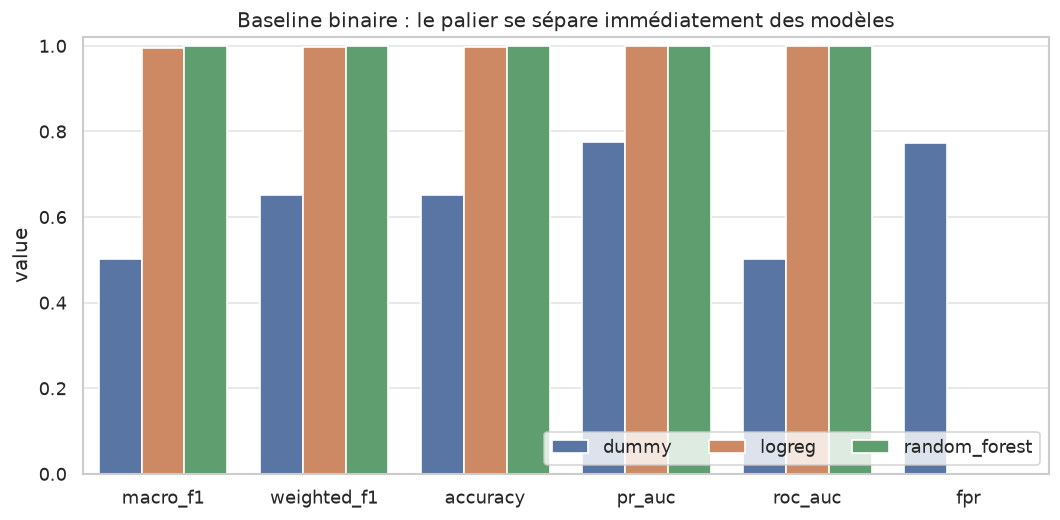

,macro_f1,pr_auc,roc_auc,fpr,fpr_at_tpr95
model,,,,,
dummy,0.5006,0.7741,0.5006,0.7736,0.9497
logreg,0.9949,0.9998,0.9994,0.0026,0.0001
random_forest,0.9991,1.0000,1.0000,0.0003,0.0000


In [34]:
# Analyse des métriques
metrics_long = results.melt(
    id_vars=["model"],
    value_vars=["macro_f1", "weighted_f1", "accuracy", "pr_auc", "roc_auc", "fpr"],
    var_name="metric",
    value_name="value",
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=metrics_long, x="metric", y="value", hue="model", ax=ax)
ax.set_ylim(0, 1.02)
ax.set_title("Baseline binaire : le palier se sépare immédiatement des modèles")
ax.set_xlabel("")
ax.legend(title="", ncol=3, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "02_baseline_metrics.png", bbox_inches="tight")
plt.show()

display(
    results[["model", "macro_f1", "pr_auc", "roc_auc", "fpr", "fpr_at_tpr95"]]
    .set_index("model")
    .round(4)
)

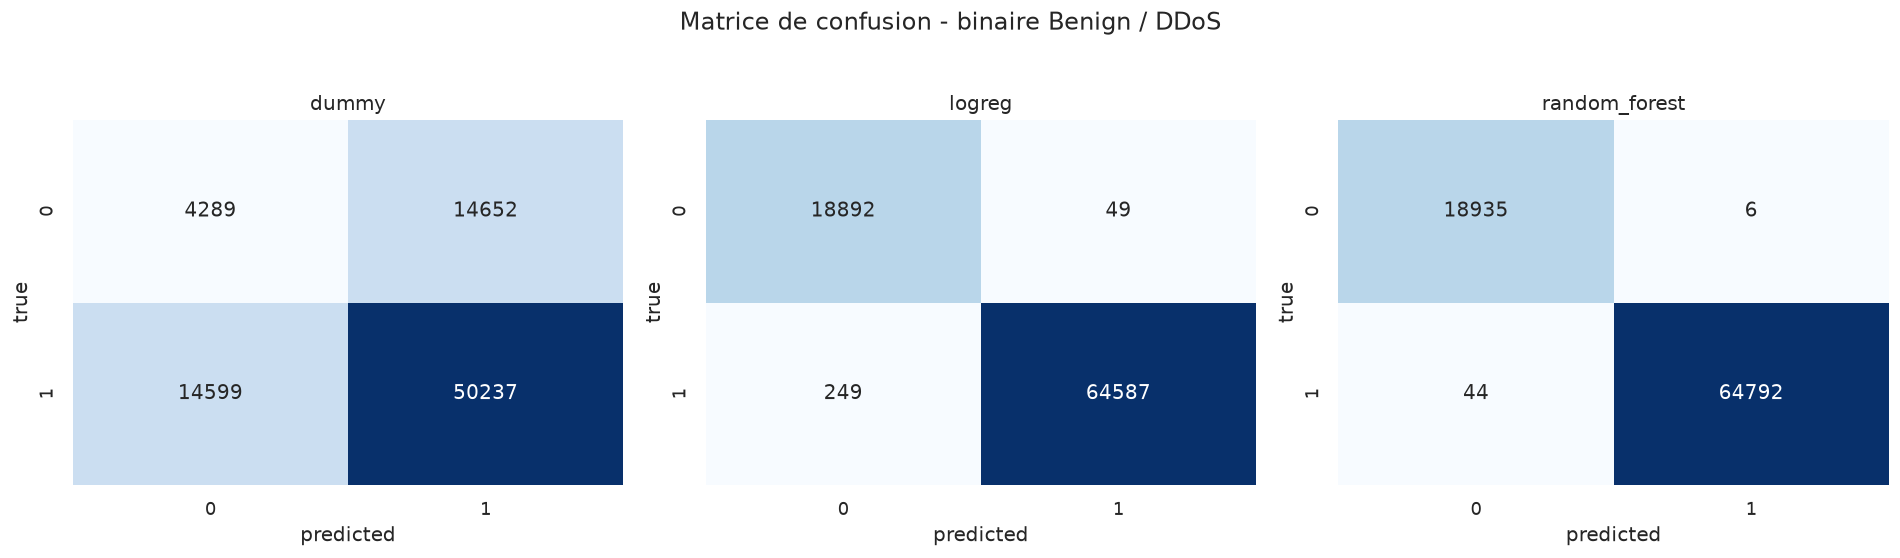

In [35]:
# Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, model in zip(axes, ["dummy", "logreg", "random_forest"]):
    matrix = pd.read_csv(RES / f"baseline_confusion_{model}.csv", index_col=0)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(model)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
fig.suptitle("Matrice de confusion - binaire Benign / DDoS", y=1.03)
fig.tight_layout()
fig.savefig(FIG / "02_baseline_confusion.png", bbox_inches="tight")
plt.show()

In [36]:
def group_attack_families(y):
    return y.astype(str).str.replace(r"^DrDoS_", "", regex=True).astype("string")

In [37]:
# L'alignement des labels : sur l’ensemble des données, le dummy stratifié atteint
# Maccro-F1 ~ 1/13, la chance pour 13 classes.  La précision suit sum(prior^2), pas 1/13, car les classes sont déséquilibrées.  Une exécution limitée peut donner un Macro-F1 différent du dummy car la limite change les priorités de classe.
X, y_family, _, _ = load_deduped()
X_train, X_test, y_family_train, y_family_test = split(X, y_family, seed=42)
y_train = group_attack_families(y_family_train)
y_test = group_attack_families(y_family_test)

dummy = DummyClassifier(strategy="stratified", random_state=42)
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)
prior = y_train.value_counts(normalize=True)
print(f"classes : {y_train.nunique()}")
print(f"1 / n_classes : {1 / y_train.nunique():.4f}")
print(f"sum(prior^2) (accuracy): {(prior ** 2).sum():.4f}")
print(f"Dummy accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Dummy Macro-F1 : {f1_score(y_test, pred, average='macro', zero_division=0):.4f}")
print("Les labels sont alignés : la précision du dummy suit sum(prior^2), pas un label regroupé.")

classes : 13
1 / n_classes : 0.0769
sum(prior^2) (accuracy): 0.2092
Dummy accuracy : 0.2082
Dummy Macro-F1 : 0.0763
Les labels sont alignés : la précision du dummy suit sum(prior^2), pas un label regroupé.


## Interprétation des résultats

**Vérification.** Le dummy binaire atteint un Macro-F1 ≈ 0,50 et une accuracy ≈ 0,65.  Le Macro-F1 est cohérent avec un tirage aléatoire à deux classes ; l’accuracy plus élevée vient du déséquilibre Benign/DDoS et ne doit pas être lue comme une performance.  Les étiquettes sont donc alignées.

**Observation.** La régression logistique et la forêt aléatoire dépassent toutes deux 0,99 de Macro-F1.  La forêt aléatoire est légèrement devant (≈ 0,999) et surtout plus prudente : son FPR tombe à ≈ 0,03 %, contre ≈ 0,26 % pour la régression logistique.  L’écart entre les deux modèles est faible comparé à l’écart qui les sépare du dummy.

**Interprétation ML.** La tâche Benign/DDoS est facile sur ce jeu de données : une frontière linéaire suffit déjà à séparer l’essentiel du trafic.  Un score binaire quasi parfait ne prouve donc pas que le modèle distingue les *types* d’attaques ; il prouve seulement qu’il sépare le trafic bénin du trafic offensif.

**Interprétation cyber.** Un détecteur binaire avec un FPR inférieur à 1 % est utile comme premier étage de triage : il réduit le volume à examiner sans noyer l’analyste.  En revanche, il ne dit pas quelle famille d’attaque est en cours et ne permet donc pas de choisir directement une mesure d’atténuation.  Cette phase ne teste que la détection Benign/DDoS ; elle ne mesure ni l’attribution de famille ni la généralisation à une famille inconnue.

**Limites.** L’ensemble de test est un échantillon aléatoire issu d’une capture de laboratoire de 2019.  Il ne mesure ni la dérive, ni l’évasion adversaire, ni le trafic chiffré.  L’accuracy est affichée, mais les conclusions reposent sur le Macro-F1, le rappel par classe et le FPR.
